# Tugas 1 — Estimasi Durasi Pengiriman (Regresi Kuantil P50/P90)

Notebook ini mengerjakan Tugas 1 langkah demi langkah. Setiap butir memanggil fungsi-fungsi di
`kode/src/regresi/` secara berurutan (urutannya sama dengan `python kode/run_all.py --stages regresi`),
menampilkan hasil yang dikembalikan setiap fungsi, lalu menyimpan JSON hasil ke `kode/results/` dan
grafik ke `kode/figures/` seperti pipeline utama.

| Butir | Isi | Modul | Penanggung jawab |
| --- | --- | --- | --- |
| 1a | Audit data dan pengukuran dampak temuan | `audit.py`, `audit_dampak.py` | Rainaldi Pakpahan |
| 1b | Desain validasi berbasis waktu vs *random K-fold* | `validation.py` | Rainaldi Pakpahan |
| 1c | Perbandingan model dan *tuning* di dalam validasi waktu | `models.py` | Firdaus Arif Ramadhani |
| 1d | Rekayasa fitur dan kategori *unseen* | `features.py` | Firdaus Arif Ramadhani |
| 1e | Kalibrasi P90 dengan *conformal prediction* | `calibration.py` | Firdaus Arif Ramadhani |
| 1f | Analisis *error*, SHAP, dan `prediksi_regresi.csv` | `analysis.py` | Firdaus Arif Ramadhani |

Metrik utama: *pinball loss* kuantil 0,5 dan 0,9 (makin kecil makin baik) serta cakupan P90
(proporsi durasi aktual ≤ P90, sasaran 90%). Seluruh langkah memakai `SEED = 42`.

## Persiapan

Sel ini menyiapkan *path*, *seed* global, dan pembantu tampilan: `ringkas()` untuk mencetak kamus hasil
fungsi, `tabel_metrik()` untuk mengubahnya menjadi tabel, dan `tampilkan_gambar()` untuk grafik. Data
dibaca dari folder `data/` di *root* repositori (atau dari variabel lingkungan `UTS_ML_DATA_DIR`).

In [1]:
import json
import sys
import warnings
from io import BytesIO
from pathlib import Path

import matplotlib

# Peringatan informatif yang tidak memengaruhi hasil (deprecation pandas, tqdm, format keluaran SHAP)
warnings.filterwarnings("ignore", message="Constructing a Categorical with a dtype")
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")

# Backend non-interaktif: grafik disimpan ke kode/figures/ lalu ditampilkan dari berkasnya
matplotlib.use("Agg")

import pandas as pd  # noqa: E402
from IPython.display import Image, Markdown, display  # noqa: E402
from PIL import Image as PILImage  # noqa: E402

# Notebook dijalankan dari kode/notebooks/; folder kode/ dimasukkan ke sys.path
KODE_DIR = Path.cwd().resolve()
if KODE_DIR.name == "notebooks":
    KODE_DIR = KODE_DIR.parent
if str(KODE_DIR) not in sys.path:
    sys.path.insert(0, str(KODE_DIR))

from src.config import FIGURES_DIR, REPO_ROOT, RESULTS_DIR, SEED  # noqa: E402
from src.utils import set_global_seed  # noqa: E402

set_global_seed(SEED)
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)


def baca_hasil(nama: str) -> dict:
    """Baca berkas JSON hasil eksperimen dari kode/results/."""
    return json.loads((RESULTS_DIR / nama).read_text(encoding="utf-8"))


def tampilkan_gambar(nama, lebar: int = 1100) -> None:
    """Tampilkan grafik dari kode/figures/ (diperkecil agar notebook tetap ringan)."""
    jalur = Path(nama)
    gambar = PILImage.open(jalur if jalur.is_absolute() else FIGURES_DIR / jalur)
    if gambar.width > lebar:
        tinggi = round(gambar.height * lebar / gambar.width)
        gambar = gambar.resize((lebar, tinggi), PILImage.LANCZOS)
    buffer = BytesIO()
    gambar.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


def ringkas(obj, maks_baris: int = 25) -> None:
    """Cetak hasil fungsi (kamus/daftar) sebagai JSON berindentasi, dipotong bila panjang."""
    baris = json.dumps(obj, indent=1, ensure_ascii=False, default=str).splitlines()
    print("\n".join(baris[:maks_baris]))
    if len(baris) > maks_baris:
        print(f"... ({len(baris) - maks_baris} baris lagi)")


def tabel_metrik(kamus: dict, kolom: list[str] | None = None) -> pd.DataFrame:
    """Ubah {nama: {metrik: nilai}} menjadi tabel (baris = nama, kolom = metrik)."""
    df = pd.DataFrame.from_dict(kamus, orient="index")
    return df[kolom] if kolom else df


print(f"Folder kode : {KODE_DIR.relative_to(REPO_ROOT)}/")
print(f"Seed global : {SEED}")

Folder kode : kode/
Seed global : 42


## 1a. Audit Data dan Pengukuran Dampak

*Penanggung jawab: Rainaldi Pakpahan*

Audit dilakukan dengan prinsip satu fungsi untuk satu pertanyaan. Data latih dan uji dimuat sekali,
lalu setiap fungsi pemeriksaan dipanggil berurutan.

In [2]:
from src.config import REGRESI_TEST_PATH, REGRESI_TRAIN_PATH
from src.regresi.audit import (
    audit_skema_dan_waktu,
    audit_tipe_dan_missing,
    cek_anomali_target,
    cek_batas_fisik_numerik,
    cek_efek_kalender,
    cek_kolom_kategorikal,
    cek_pemulihan_rute_jarak,
    cek_pergeseran_bulanan,
    kelompokkan_kuadran_detektif,
    plot_bukti_leakage_scan,
    plot_bukti_target_menit,
    plot_pergeseran_temporal,
    screening_kolom_numerik,
    simpan_ringkasan_audit_1a,
)
from src.regresi.audit_dampak import jalankan_semua_dampak

train = pd.read_csv(REGRESI_TRAIN_PATH)
test = pd.read_csv(REGRESI_TEST_PATH)
print(f"train: {train.shape[0]:,} baris x {train.shape[1]} kolom")
print(f"test : {test.shape[0]:,} baris x {test.shape[1]} kolom")

train: 250,000 baris x 77 kolom
test : 60,000 baris x 76 kolom


**1a.1 Skema, duplikat, keacakan ID, dan rentang waktu** — `audit_skema_dan_waktu()`

In [3]:
ringkas(audit_skema_dan_waktu(train, test), maks_baris=40)

{
 "skema": {
  "train_shape": [
   250000,
   77
  ],
  "test_shape": [
   60000,
   76
  ],
  "train_only_cols": [
   "durasi_jam"
  ],
  "test_only_cols": []
 },
 "duplikat": {
  "dup_id_train": 0,
  "dup_id_test": 0,
  "overlap_id_train_test": 0,
  "dup_rows_train": 0
 },
 "keacakan_id": {
  "id_corr_row_index": -0.00089,
  "id_corr_target_spearman": -0.002
 },
 "waktu": {
  "invalid_date_train": 0,
  "invalid_date_test": 0,
  "train_date_range": [
   "2025-01-01",
   "2025-08-31"
  ],
  "test_date_range": [
   "2025-09-01",
   "2025-10-31"
  ],
  "train_monthly_counts": {
   "2025-01": 29985,
   "2025-02": 27556,
   "2025-03": 32829,
... (12 baris lagi)


**1a.2 Tipe data dan pola nilai kosong** — `audit_tipe_dan_missing()`

In [4]:
ringkas(audit_tipe_dan_missing(train, test), maks_baris=40)

{
 "tipe_data": {
  "n_numeric_features": 68,
  "text_columns": [
   "id_paket",
   "tgl_pickup",
   "layanan",
   "mitra_kurir",
   "hub_asal",
   "kota_asal",
   "pulau_tujuan",
   "kota_tujuan"
  ],
  "dtype_mismatches": {},
  "target_dtype": "float64"
 },
 "missing_values": {
  "berat_kg": {
   "train_n": 13897,
   "train_pct": 5.56,
   "test_n": 3265,
   "test_pct": 5.44
  }
 },
 "pola_missing": {
  "berat_kg": {
   "missing_pct_by_category": {
    "layanan": {
     "ekspres": 2.55,
     "hemat": 2.55,
     "kargo": 32.87,
     "reguler": 2.5
    },
    "hub_asal": {
     "BDG": 5.5,
     "JKT": 5.43,
     "MDN": 5.8,
     "MKS": 5.69,
     "SBY": 5.63,
     "SMG": 5.61
... (35 baris lagi)


**1a.3 *Screening* *leakage* dan pergeseran** — `screening_kolom_numerik()` membandingkan setiap kolom
numerik dengan target (Spearman) dan dengan data uji (KS); `kelompokkan_kuadran_detektif()` memetakan
hasilnya ke empat kuadran.

,kolom,ks_train_vs_test,spearman_target,train_min,train_median,train_max,test_min,test_median,test_max
0,jam_pickup,0.0042,0.0113,0.000,12.000,2.3000e+01,0.000,12.000,2.3000e+01
1,jarak_km,0.0063,0.4982,0.000,741.600,9.9990e+03,0.000,735.100,9.9990e+03
2,berat_kg,0.0054,0.0688,0.020,1.310,6.8334e+02,0.030,1.310,3.8508e+02
3,volume_liter,0.0040,0.0962,0.100,5.500,4.5968e+03,0.100,5.500,2.5077e+03
4,jumlah_item,0.0029,0.0781,1.000,2.000,1.4000e+01,1.000,2.000,1.1000e+01
5,nilai_barang,0.0039,0.0485,2000.000,276000.000,4.8400e+07,4000.000,274000.000,4.8994e+07
6,asuransi,0.0006,0.0293,0.000,0.000,1.0000e+00,0.000,0.000,1.0000e+00
7,cod,0.0028,0.0824,0.000,0.000,1.0000e+00,0.000,0.000,1.0000e+00
8,alamat_skor,0.0063,-0.1061,0.041,0.818,1.0000e+00,0.093,0.817,1.0000e+00
9,pengalaman_kurir_bulan,0.0040,-0.0555,0.000,13.500,1.1170e+02,0.100,13.500,1.3020e+02


{
 "tersangka_leakage": [
  "jumlah_scan"
 ],
 "drift_bersinyal": [
  "antrean_hub_asal",
  "f17",
  "f35"
 ],
 "drift_noise": [
  "f30"
 ],
 "sinyal_stabil": [
  "jarak_km",
  "f04",
  "f05",
  "f22",
  "f23",
  "f09",
  "alamat_skor",
  "volume_liter",
  "f28",
  "cod",
  "jumlah_item",
  "berat_kg",
... (55 baris lagi)


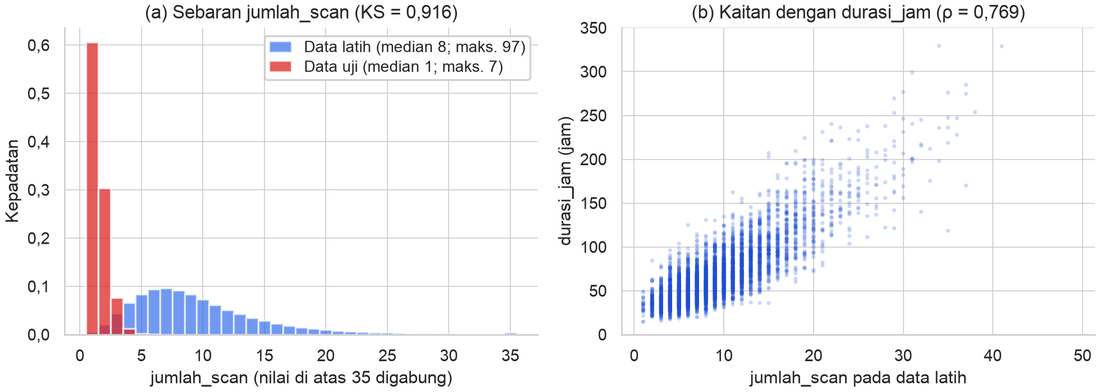

In [5]:
tabel_screening = screening_kolom_numerik(train, test)
display(tabel_screening.head(10))
ringkas(kelompokkan_kuadran_detektif(tabel_screening))
tampilkan_gambar(plot_bukti_leakage_scan(train, test))

**1a.4 Target dan batas fisik** — durasi yang tercatat dalam menit (`cek_anomali_target()`), nilai
di luar batas fisik (`cek_batas_fisik_numerik()`), dan pemulihan `jarak_km` dari rute
(`cek_pemulihan_rute_jarak()`).

{
 "n_le_zero": 0,
 "kuantil_mentah": {
  "0.0": 11.6,
  "0.01": 23.5,
  "0.5": 61.7,
  "0.9": 117.8,
  "0.99": 224.7,
  "0.999": 3054.02,
  "1.0": 25452.0
 },
 "n_gt_ambang": 370,
 "pct_gt_ambang": 0.148,
 "maks_sah_le_ambang": 693.1,
 "min_ekstrem_gt_ambang": 1272.0,
 "pct_kelipatan_6": 100.0,
 "suspicious_le_ambang_low_scan": 0,
 "mean_mentah": 77.84,
 "mean_setelah_koreksi": 71.27,
 "median_bersih": 61.6,
 "median_ekstrem_dibagi_60": 64.1,
 "median_jam_per_scan_bersih": 7.433,
 "median_jam_per_scan_koreksi": 7.288
}


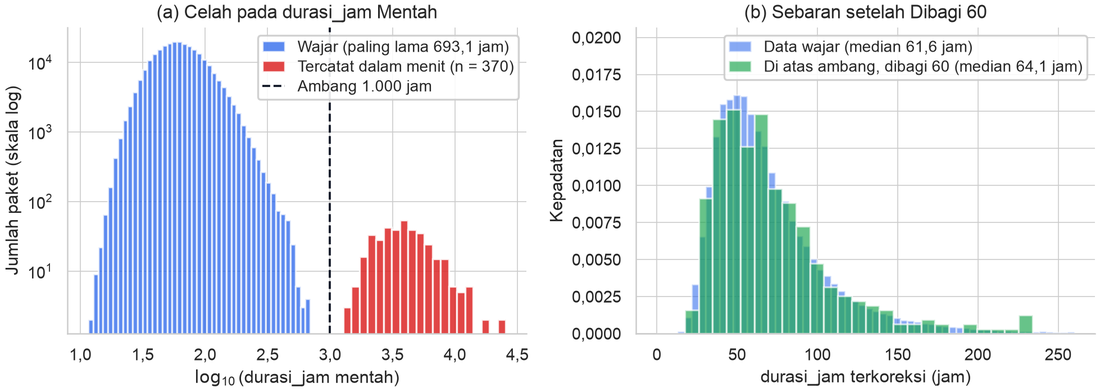

,kolom,train_min,train_med,train_max,test_min,test_max,cek_fisik,melanggar_tr,melanggar_te
0,jam_pickup,0.000,12.000,2.3000e+01,0.000,2.3000e+01,"di luar [0,23]",0,0
1,jarak_km,0.000,741.600,9.9990e+03,0.000,9.9990e+03,==0 atau >=9999,1159,307
2,berat_kg,0.020,1.310,6.8334e+02,0.030,3.8508e+02,<=0,0,0
3,volume_liter,0.100,5.500,4.5968e+03,0.100,2.5077e+03,<=0,0,0
4,jumlah_item,1.000,2.000,1.4000e+01,1.000,1.1000e+01,<1,0,0
5,nilai_barang,2000.000,276000.000,4.8400e+07,4000.000,4.8994e+07,<=0,0,0
6,asuransi,0.000,0.000,1.0000e+00,0.000,1.0000e+00,"bukan {0,1}",0,0
7,cod,0.000,0.000,1.0000e+00,0.000,1.0000e+00,"bukan {0,1}",0,0
8,alamat_skor,0.041,0.818,1.0000e+00,0.093,1.0000e+00,"di luar [0,1]",0,0
9,pengalaman_kurir_bulan,0.000,13.500,1.1170e+02,0.100,1.3020e+02,<0,0,0


{
 "train_nol": 703,
 "train_9999": 456,
 "train_total_rusak": 1159,
 "train_pct_rusak": 0.464,
 "test_nol": 177,
 "test_9999": 130,
 "test_total_rusak": 307,
 "test_pct_rusak": 0.512,
 "jumlah_rute_valid_train": 10979,
 "max_nunique_per_rute": 1,
 "max_std_per_rute": 0.0,
 "test_rusak_terpulihkan_eksak": 305,
 "test_rusak_terpulihkan_pct": 99.35
}


In [6]:
ringkas(cek_anomali_target(train))
tampilkan_gambar(plot_bukti_target_menit(train))
display(cek_batas_fisik_numerik(train, test))
ringkas(cek_pemulihan_rute_jarak(train, test))

**1a.5 Kategori dan kalender** — kategori *unseen* dan kardinalitas tinggi, pergeseran bulanan per kurir
dan hub, serta efek Lebaran dan tanggal kembar.

{
 "ringkasan_kategori": "          kolom  unik_train  unik_train_norm  unik_test  unik_test_norm unseen_di_test  baris_unseen  pct_unseen_test\n0       layanan           4                4          4               4             []             0              0.0\n1   mitra_kurir          12               12         13              13          [K13]          2342              3.9\n2      hub_asal           6                6          6               6             []             0              0.0\n3     kota_asal          30               30         30              30             []             0              0.0\n4  pulau_tujuan           7                7          7               7             []             0              0.0\n5   kota_tujuan         405              405        405             405             []             0              0.0",
 "max_hub_per_kota_asal": 1,
 "max_pulau_per_kota_tujuan": 1,
 "min_baris_kota_tujuan_train": 37,
 "kota_tujuan_kurang_50_baris": 16
}


{
 "f35_per_kurir_bulan": "_ym          2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  2025-07  2025-08  2025-09  2025-10\nmitra_kurir                                                                                          \nK01            0.944    0.944    0.944    0.944    0.943    0.945    0.946    0.943    0.942    0.944\nK02            1.080    1.080    1.078    1.078    1.079    1.078    1.079    1.079    1.079    1.081\nK03            1.064    1.064    1.063    1.062    1.066    1.063    1.064    1.062    1.064    1.065\nK04            0.970    0.970    0.968    0.970    0.970    0.968    0.970    0.970    0.971    0.971\nK05            1.033    1.034    1.033    1.035    1.035    1.034    1.036    1.035    1.035    1.034\nK06            1.026    1.027    1.026    1.026    1.026    1.027    1.027    1.029    1.029    1.025\nK07            0.985    0.987    0.985    0.986    0.988    0.984    1.282    1.278    1.280    1.282\nK08            0.856    0.855    0.855    0.85

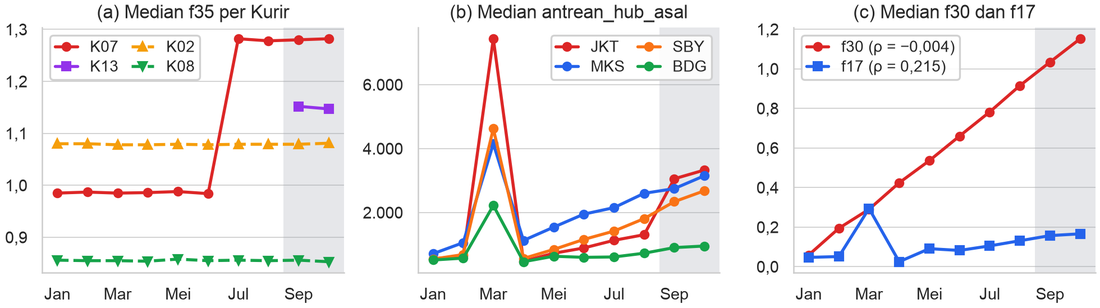

In [7]:
ringkas(cek_kolom_kategorikal(train, test))
ringkas(cek_pergeseran_bulanan(train, test))
ringkas(cek_efek_kalender(train))
tampilkan_gambar(plot_pergeseran_temporal(train, test))

**1a.6 Pengukuran dampak** — `jalankan_semua_dampak()` melatih model yang sama dengan dan tanpa setiap
perbaikan (*train* Januari–Juni, validasi Juli–Agustus); `simpan_ringkasan_audit_1a()` menulis
`task1_audit.json`. Bandingkan *pinball* P50/P90 dan cakupan P90 antarvarian dalam eksperimen yang sama.

Ringkasan 1a tersimpan di kode/results/task1_audit.json


pinball_p50  pinball_p90  p90_coverage  mae_p50     rmse      mae  mean_bias
exp1_leakage_jumlah_scan dengan_scan_cv_naif              5.4229       2.9634        0.8746  10.8458      NaN      NaN        NaN
                         dengan_scan_simulasi_test       10.5022      13.4648        0.4291  21.0044      NaN      NaN        NaN
                         tanpa_scan_jujur                 6.8913       4.4414        0.8742  13.7825      NaN      NaN        NaN
exp2_satuan_target       ridge_target_mentah              9.1913          NaN           NaN      NaN  27.1426  18.3826     5.0917
                         ridge_target_koreksi_60          8.4073          NaN           NaN      NaN  26.5609  16.8146    -0.9788
                         lgbm_target_mentah               6.8831       4.4457        0.8761  13.7662      NaN      NaN        NaN
                         lgbm_target_koreksi_60           6.8913       4.4414        0.8742  13.7825      NaN      NaN        NaN
exp3_pemulihan_jarak_km  subset_sentinel_mentah          10.1310       7.6887        0.8917  20.2621      NaN      NaN        NaN
                         subset_sentinel_dipulihkan       8.0039       6.6483        0.8790  16.0078      NaN      NaN        NaN
                         global_mentah                    6.8967       4.4367        0.8755  13.7934      NaN      NaN        NaN
                         global_dipulihkan                6.8913       4.4414        0.8742  13.7825      NaN      NaN        NaN
exp5_seleksi_fitur_f     semua_50_fitur_f                 6.8913       4.4414        0.8742  13.7825      NaN      NaN        NaN
                         hanya_10_fitur_sinyal_f          6.8684       4.4139        0.8750  13.7368      NaN      NaN        NaN

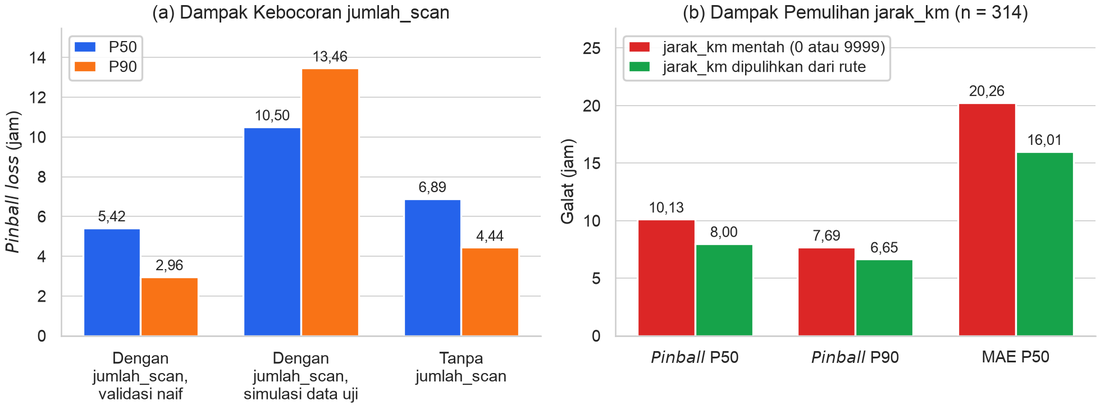

In [8]:
hasil_dampak = jalankan_semua_dampak(train, test)
jalur = simpan_ringkasan_audit_1a(train, test, hasil_dampak=hasil_dampak)
print("Ringkasan 1a tersimpan di", jalur.relative_to(REPO_ROOT))

baris = {}
for eksperimen, isi in hasil_dampak.items():
    if not eksperimen.startswith("exp") or not isinstance(isi, dict):
        continue
    for varian, metrik in isi.items():
        if isinstance(metrik, dict) and all(not isinstance(v, (dict, list)) for v in metrik.values()):
            baris[(eksperimen, varian)] = metrik
display(pd.DataFrame.from_dict(baris, orient="index"))
tampilkan_gambar(hasil_dampak["grafik_dampak"])

## 1b. Desain Validasi Berbasis Waktu

*Penanggung jawab: Rainaldi Pakpahan*

Data uji berada pada September–Oktober 2025, sehingga validasi meniru pemakaian nyata: model dilatih
pada bulan-bulan sebelumnya lalu memprediksi dua bulan berikutnya (*expanding-window time-based CV*,
3 *fold*). Skema ini dibandingkan dengan *random* 5-*fold* CV memakai model dan fitur yang identik
untuk menunjukkan seberapa optimistis validasi acak.

In [9]:
from src.regresi.validation import evaluasi_random_kfold, evaluasi_validasi_waktu, plot_perbandingan_validasi
from src.utils import save_json

hasil_waktu = evaluasi_validasi_waktu(train, seed=SEED)
display(Markdown("**Time CV: rincian per fold**"))
display(pd.DataFrame(hasil_waktu["per_fold"]))

**Time CV: rincian per fold**

,n_train,n_val,pinball_p50,pinball_p90,p90_coverage,mae_p50,fold,periode_train,periode_val
0,57541,59073,7.7259,5.5699,0.7972,15.4517,Fold 1 (Mar–Apr),2025-01-01..2025-02-28,2025-03-01..2025-04-30
1,116614,64782,6.4519,4.2150,0.9064,12.9038,Fold 2 (Mei–Jun),2025-01-01..2025-04-30,2025-05-01..2025-06-30
2,181396,68604,6.8813,4.4086,0.8757,13.7625,Fold 3 (Jul–Agu),2025-01-01..2025-06-30,2025-07-01..2025-08-31


In [10]:
hasil_random = evaluasi_random_kfold(train, n_splits=5, seed=SEED)
display(Markdown("**Ringkasan rata-rata dan simpangan baku per skema**"))
display(tabel_metrik({
    "Time CV (3 fold)": hasil_waktu["ringkasan"],
    "Random 5-fold": hasil_random["ringkasan"],
}))

**Ringkasan rata-rata dan simpangan baku per skema**

,pinball_p50_mean,pinball_p50_std,pinball_p90_mean,pinball_p90_std,p90_coverage_mean,p90_coverage_std,mae_p50_mean,mae_p50_std
Time CV (3 fold),7.0197,0.5292,4.7312,0.5983,0.8598,0.0460,14.0393,1.0584
Random 5-fold,6.6424,0.0410,4.3004,0.0539,0.8855,0.0014,13.2849,0.0820


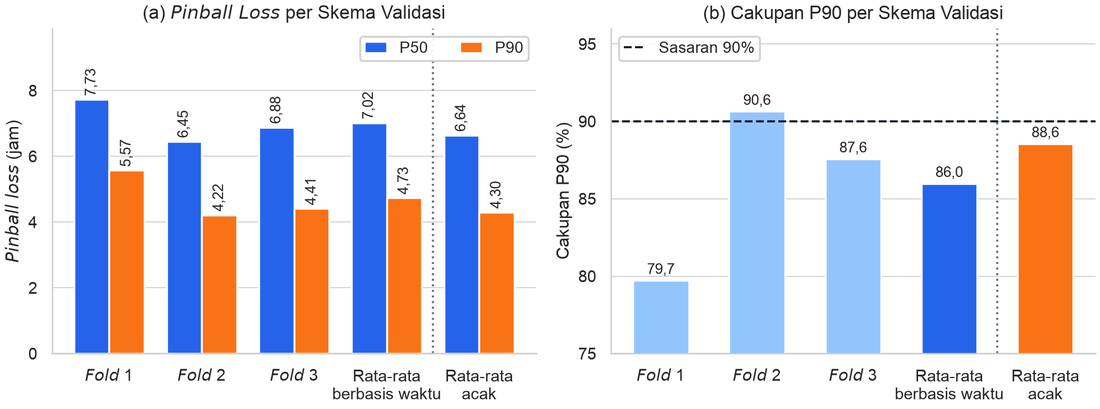

In [11]:
grafik_validasi = plot_perbandingan_validasi(hasil_waktu, hasil_random)
save_json(
    {
        "task": "Tugas 1b — Desain Validasi Berbasis Waktu vs Random K-Fold",
        "seed": SEED,
        "time_based_cv": hasil_waktu,
        "random_kfold_cv": hasil_random,
        "figure": grafik_validasi.name,
    },
    RESULTS_DIR / "task1_validation.json",
)
tampilkan_gambar(grafik_validasi)

## 1c. Perbandingan Model dan *Tuning* di Dalam Validasi Waktu

*Penanggung jawab: Firdaus Arif Ramadhani*

Satu *baseline* dan empat keluarga model dibandingkan pada skema validasi 1b; semua *tuning* dilakukan
di dalam *fold* waktu agar tidak bocor:

0. *Baseline* kuantil empiris per `(layanan, pulau_tujuan)`.
1. Ridge pada `log(durasi_jam)` dengan kuantil residual per layanan.
2. LightGBM *quantile*.
3. CatBoost *MultiQuantile*.
4. XGBoost *MultiQuantile*.
5. *Ensemble* konveks dari model terbaik, dengan bobot terpisah untuk P50 dan P90.

Prediksi *out-of-fold* disimpan ke `kode/cache/` dan dipakai lagi oleh butir 1e dan 1f.

In [7]:
%run ../src/regresi/models.py

[START] Menyiapkan 3 fold Time CV dengan feature pipeline anti-leakage


[DONE]  Menyiapkan 3 fold Time CV dengan feature pipeline anti-leakage (4.20s)
[START] Model 0: Baseline Group Quantile (layanan x pulau_tujuan)


[DONE]  Model 0: Baseline Group Quantile (layanan x pulau_tujuan) (0.24s)
[START] Model 1: Log-Target Ridge Quantile (tuning alpha)


[DONE]  Model 1: Log-Target Ridge Quantile (tuning alpha) (15.25s)
[START] Model 2: LightGBM Quantile (tuning di dalam 3-fold Time CV)


[DONE]  Model 2: LightGBM Quantile (tuning di dalam 3-fold Time CV) (320.30s)
[START] Model 3: CatBoost MultiQuantile (tuning di dalam 3-fold Time CV)


[DONE]  Model 3: CatBoost MultiQuantile (tuning di dalam 3-fold Time CV) (261.96s)
[START] Model 4: XGBoost MultiQuantile (tuning di dalam 3-fold Time CV)


[DONE]  Model 4: XGBoost MultiQuantile (tuning di dalam 3-fold Time CV) (73.74s)



================ RINGKASAN MODEL TUGAS 1c (TIME CV) ================
  baseline     | Mean3F: P50=10.4331, P90=6.4320, cov=88.05% | Fold3(Jul-Agu): P50=10.4868, P90=6.4582, cov=88.91%
  log_ridge    | Mean3F: P50=7.2914, P90=4.6816, cov=87.08% | Fold3(Jul-Agu): P50=7.0002, P90=4.3816, cov=89.03%
  lgbm         | Mean3F: P50=7.0020, P90=4.6643, cov=85.13% | Fold3(Jul-Agu): P50=6.7549, P90=4.2688, cov=87.56%
  catboost     | Mean3F: P50=6.9916, P90=4.6008, cov=85.40% | Fold3(Jul-Agu): P50=6.6918, P90=4.2098, cov=87.75%
  xgboost      | Mean3F: P50=7.1781, P90=4.7789, cov=85.93% | Fold3(Jul-Agu): P50=6.9269, P90=4.4119, cov=88.07%
  ensemble     | Mean3F: P50=6.9557, P90=4.5477, cov=86.52% | Fold3(Jul-Agu): P50=6.6932, P90=4.1998, cov=88.87%

Bobot Ensemble Final (3-fold OOF):
  P50: {'log_ridge': 0.0794, 'lgbm': 0.4232, 'catboost': 0.4974, 'xgboost': 0.0}
  P90: {'log_ridge': 0.3407, 'lgbm': 0.1143, 'catboost': 0.5451, 'xgboost': 0.0}

Grafik: kode/figures/task1_1c_model_comparison.png


,pinball_p50_mean,pinball_p90_mean,p90_coverage_mean,fold3_pinball_p50,fold3_pinball_p90,fold3_p90_coverage
baseline,10.4331,6.4320,0.8805,10.4868,6.4582,0.8891
catboost,6.9916,4.6008,0.8540,6.6918,4.2098,0.8775
ensemble,6.9557,4.5477,0.8652,6.6932,4.1998,0.8887
lgbm,7.0020,4.6643,0.8513,6.7549,4.2688,0.8756
log_ridge,7.2914,4.6816,0.8708,7.0002,4.3816,0.8903
xgboost,7.1781,4.7789,0.8593,6.9269,4.4119,0.8807


**Bobot *ensemble* final (dioptimalkan pada OOF 3 fold)**

,P50,P90
catboost,0.4974,0.5451
lgbm,0.4232,0.1143
log_ridge,0.0794,0.3407
xgboost,0.0000,0.0000


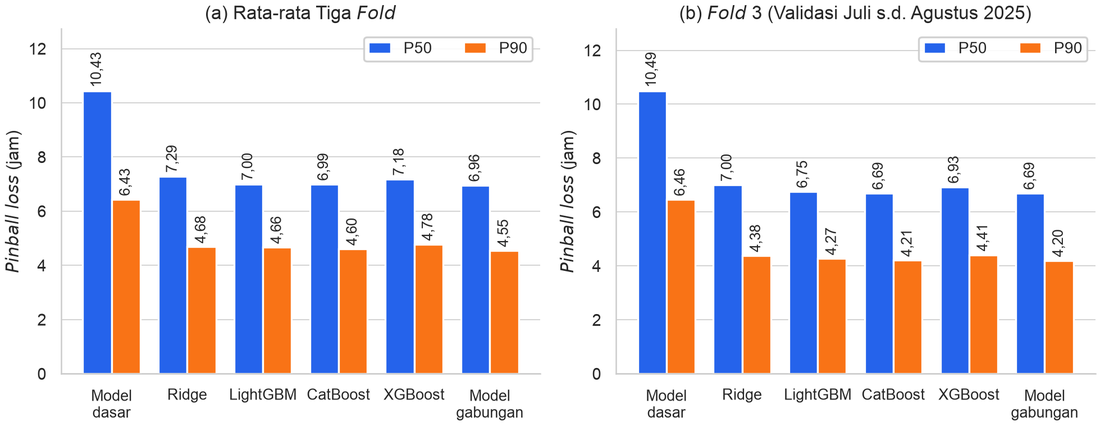

In [8]:
model = baca_hasil("task1_models.json")
kolom = [
    "pinball_p50_mean", "pinball_p90_mean", "p90_coverage_mean",
    "fold3_pinball_p50", "fold3_pinball_p90", "fold3_p90_coverage",
]
display(tabel_metrik({nama: isi["ringkasan"] for nama, isi in model["models"].items()}, kolom))
ensemble = model["models"]["ensemble"]
display(Markdown("**Bobot *ensemble* final (dioptimalkan pada OOF 3 fold)**"))
display(pd.DataFrame({
    "P50": ensemble["weights_p50_final_all3"],
    "P90": ensemble["weights_p90_final_all3"],
}))
tampilkan_gambar(model["figure"])

## 1d. Rekayasa Fitur dan Kategori *Unseen*

*Penanggung jawab: Firdaus Arif Ramadhani*

Fitur dibangun dari waktu *pickup* (tanpa informasi masa depan). Dua tantangan kategori ditangani:

- **Kardinalitas tinggi** (`kota_tujuan` dan rute `hub_asal × kota_tujuan`): *hierarchical smoothed
  target encoding* *out-of-fold* dengan *shrinkage* bertingkat ke `pulau_tujuan` lalu ke rata-rata global.
- **Kurir *unseen*** (`mitra_kurir = K13` hanya ada di data uji): diuji lewat simulasi
  *leave-one-courier-out*; tiga kurir disembunyikan dari data latih lalu tiga strategi dibandingkan.

In [9]:
%run ../src/regresi/features.py --test-unseen

[START] Simulasi Leave-One-Courier-Out (K08, K02, K07)


[DONE]  Simulasi Leave-One-Courier-Out (K08, K02, K07) (46.13s)

=== HASIL SIMULASI KURIR UNSEEN (TUGAS 1d) ===
  tanpa_f35_fallback_global    -> P50=8.5449 | P90=5.8559 | cov90=74.54%
      K08 (f35=0.855): P50=6.908, bias=+7.55 jam
      K02 (f35=1.079): P50=7.230, bias=-4.56 jam
      K07 (f35=1.280): P50=11.986, bias=-15.88 jam
  mitra_kurir_plus_f35         -> P50=8.2899 | P90=5.4851 | cov90=77.07%
      K08 (f35=0.855): P50=6.641, bias=+6.64 jam
      K02 (f35=1.079): P50=7.176, bias=-4.17 jam
      K07 (f35=1.280): P50=11.434, bias=-14.77 jam
  hanya_f35_tanpa_id_kurir     -> P50=7.7243 | P90=5.0598 | cov90=80.77%
      K08 (f35=0.855): P50=6.184, bias=+4.95 jam
      K02 (f35=1.079): P50=6.968, bias=-2.59 jam
      K07 (f35=1.280): P50=10.228, bias=-11.27 jam


Kurir yang disembunyikan: K08, K02, K07
Baris validasi kurir unseen: 18,534


,overall_p90_coverage,overall_pinball_p50,overall_pinball_p90
hanya_f35_tanpa_id_kurir,0.8077,7.7243,5.0598
mitra_kurir_plus_f35,0.7707,8.2899,5.4851
tanpa_f35_fallback_global,0.7454,8.5449,5.8559


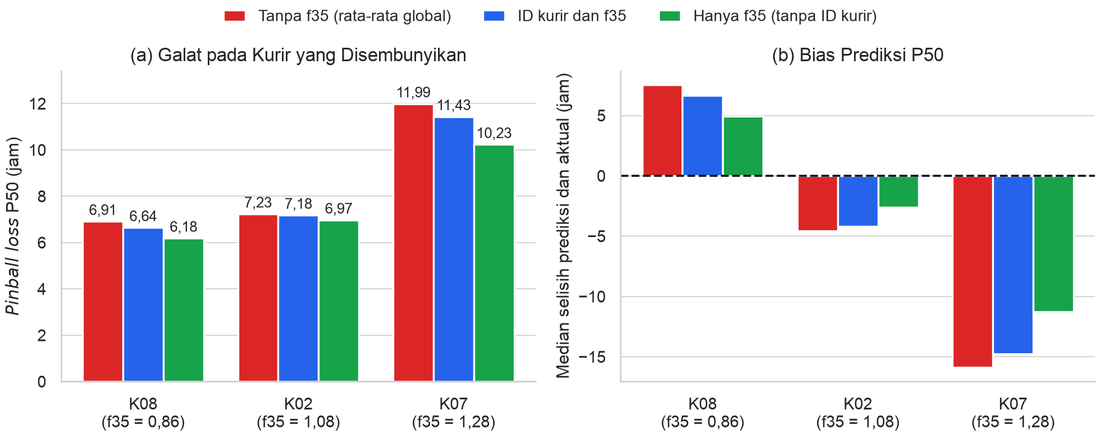

In [10]:
kurir = baca_hasil("task1_unseen_courier.json")
print("Kurir yang disembunyikan:", ", ".join(kurir["heldout_couriers"]))
print(f"Baris validasi kurir unseen: {kurir['n_val_unseen_rows']:,}")
display(tabel_metrik(
    {nama: {k: v for k, v in isi.items() if k != "per_kurir_unseen"} for nama, isi in kurir["strategi"].items()}
))
tampilkan_gambar(kurir["figure"])

## 1e. Kalibrasi P90 dengan *Conformal Prediction*

*Penanggung jawab: Firdaus Arif Ramadhani*

P90 mentah dari model belum tentu mencakup 90% durasi aktual. Tiga varian *one-sided conformalized
quantile regression* (CQR) dibandingkan secara kronologis: kalibrasi pada Juli 2025, evaluasi pada
Agustus 2025.

- **Aditif:** `p90 + delta` global.
- **Multiplikatif:** `m × p90` global.
- **Multiplikatif per kelompok:** faktor `m` terpisah per `layanan` agar cakupan merata.

In [11]:
%run ../src/regresi/calibration.py

=== HASIL KALIBRASI CONFORMAL P90 (KALIBRASI JUL -> UJI AGU 2025) ===

[LGBM]
  uncalibrated               -> Pinball P90=4.2604 | cov90=87.68% (gap=2.32%) | lebar_med=18.76 jam
  additive_cqr               -> Pinball P90=4.2260 | cov90=90.07% (gap=0.07%) | lebar_med=21.99 jam
  multiplicative_cqr         -> Pinball P90=4.2121 | cov90=90.11% (gap=0.11%) | lebar_med=21.71 jam
  group_multiplicative_cqr   -> Pinball P90=4.2125 | cov90=90.07% (gap=0.07%) | lebar_med=21.74 jam

[CATBOOST]
  uncalibrated               -> Pinball P90=4.2205 | cov90=87.68% (gap=2.32%) | lebar_med=18.66 jam
  additive_cqr               -> Pinball P90=4.1872 | cov90=89.79% (gap=0.21%) | lebar_med=21.41 jam
  multiplicative_cqr         -> Pinball P90=4.1773 | cov90=89.70% (gap=0.30%) | lebar_med=21.23 jam
  group_multiplicative_cqr   -> Pinball P90=4.1780 | cov90=89.66% (gap=0.34%) | lebar_med=21.12 jam

[ENSEMBLE]
  uncalibrated               -> Pinball P90=4.2090 | cov90=88.78% (gap=1.22%) | lebar_med=20.24 ja

**Evaluasi Agustus 2025 pada *ensemble***

,pinball_p90,p90_coverage,abs_cov_gap_pct,median_interval_width
additive_cqr,4.1988,0.8978,0.22,21.71
group_multiplicative_cqr,4.1884,0.8980,0.20,21.65
multiplicative_cqr,4.1885,0.8977,0.23,21.58
uncalibrated,4.2090,0.8878,1.22,20.24


Metode terpilih: group_multiplicative_cqr


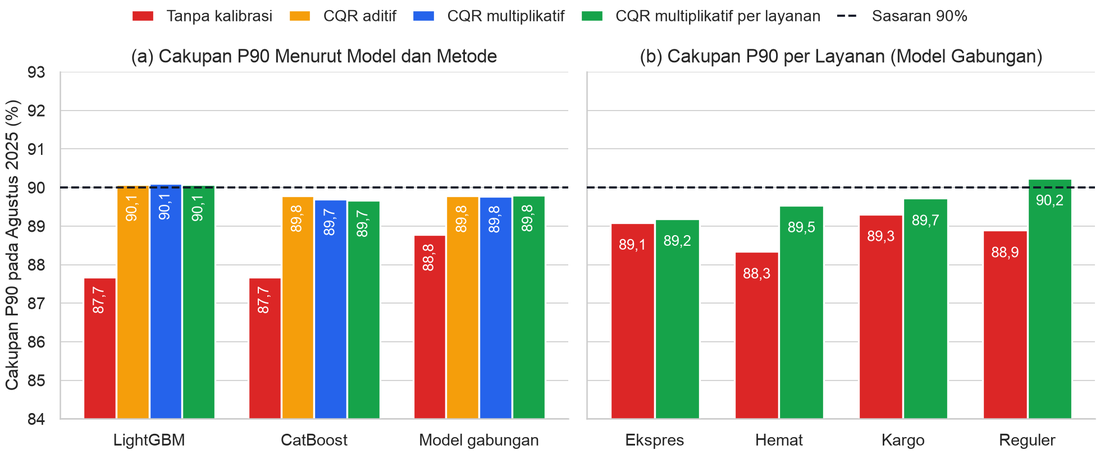

In [12]:
kalibrasi = baca_hasil("task1_calibration.json")
kolom = ["pinball_p90", "p90_coverage", "abs_cov_gap_pct", "median_interval_width"]
display(Markdown("**Evaluasi Agustus 2025 pada *ensemble***"))
display(tabel_metrik(kalibrasi["per_model_aug_eval"]["ensemble"], kolom))
print("Metode terpilih:", kalibrasi["final_calibration_params"]["selected_method"])
tampilkan_gambar(kalibrasi["figure"])

## 1f. Analisis *Error*, SHAP, dan Prediksi Akhir

*Penanggung jawab: Firdaus Arif Ramadhani*

Langkah terakhir Tugas 1:

1. *Breakdown error* per `layanan`, `pulau_tujuan`, dan `mitra_kurir` pada OOF *fold* 3 (Juli–Agustus)
   yang sudah dikalibrasi.
2. Interpretasi dengan `shap.TreeExplainer` pada LightGBM P50 dan P90.
3. Pelatihan ulang *ensemble* pada seluruh data latih, penerapan kalibrasi 1e, lalu penulisan
   `prediksi_regresi.csv` beserta pemeriksaan kontraknya.

In [13]:
%run ../src/regresi/analysis.py

[START] Analisis breakdown error (layanan, pulau_tujuan, mitra_kurir)


[DONE]  Analisis breakdown error (layanan, pulau_tujuan, mitra_kurir) (0.34s)
[START] Analisis SHAP pada LightGBM Quantile P50 & P90


[DONE]  Analisis SHAP pada LightGBM Quantile P50 & P90 (29.38s)
[START] Pelatihan Ensemble final (100% train) & generasi prediksi_regresi.csv


[DONE]  Pelatihan Ensemble final (100% train) & generasi prediksi_regresi.csv (106.53s)

================ RINGKASAN TUGAS 1f ================
Breakdown Error Fold 3 Terkalibrasi (by layanan):
  hemat      (n=22,760) -> P50=8.5781 | P90=4.9460 | cov90=90.0% | bias=-1.15
  kargo      (n= 6,867) -> P50=7.5974 | P90=4.7014 | cov90=90.0% | bias=-0.83
  reguler    (n=28,871) -> P50=5.8265 | P90=3.7673 | cov90=90.0% | bias=-0.62
  ekspres    (n=10,106) -> P50=4.3095 | P90=3.2632 | cov90=90.0% | bias=-0.30

Breakdown Error Fold 3 Terkalibrasi (by pulau_tujuan):
  Papua                (n= 1,226) -> P50=20.6643 | P90=11.3253 | cov90=87.7%
  Maluku               (n= 1,341) -> P50=13.6411 | P90=7.3568 | cov90=89.4%
  Kalimantan           (n= 3,868) -> P50=10.9494 | P90=6.1705 | cov90=87.8%
  Sulawesi             (n= 4,532) -> P50=10.2595 | P90=5.6462 | cov90=88.3%
  Bali-Nusa Tenggara   (n= 2,659) -> P50=7.7639 | P90=4.5013 | cov90=88.6%
  Sumatera             (n= 9,178) -> P50=7.2225 | P90=4.4381

**Error fold 3 terkalibrasi per layanan**

,bias_median,layanan,mae_p50,median_aktual,median_p50,n,p90_coverage,pinball_p50,pinball_p90
0,-1.15,hemat,17.16,74.5,71.92,22760,0.9000,8.5781,4.9460
1,-0.83,kargo,15.19,79.2,77.10,6867,0.9002,7.5974,4.7014
2,-0.62,reguler,11.65,58.6,56.70,28871,0.9000,5.8265,3.7673
3,-0.30,ekspres,8.62,39.7,38.50,10106,0.9001,4.3095,3.2632


**Error fold 3 terkalibrasi per pulau tujuan**

,bias_median,mae_p50,median_aktual,median_p50,n,p90_coverage,pinball_p50,pinball_p90,pulau_tujuan
0,-4.77,41.33,164.25,166.19,1226,0.8768,20.6643,11.3253,Papua
1,-0.93,27.28,116.90,119.68,1341,0.8941,13.6411,7.3568,Maluku
2,-1.64,21.90,92.50,91.83,3868,0.8785,10.9494,6.1705,Kalimantan
3,-1.36,20.52,89.40,90.28,4532,0.8833,10.2595,5.6462,Sulawesi
4,-1.22,15.53,66.50,64.35,2659,0.8857,7.7639,4.5013,Bali-Nusa Tenggara
5,-0.47,14.44,64.20,62.91,9178,0.8944,7.2225,4.4381,Sumatera
6,-0.60,10.47,56.70,55.12,45800,0.9063,5.2352,3.5086,Jawa


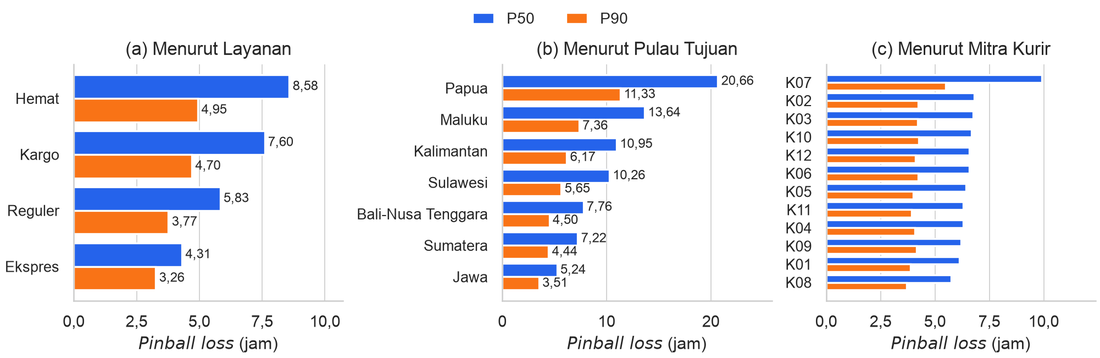

**15 fitur dengan rata-rata |SHAP| terbesar**

,P50,P90
te_rute_log_mean,0.1785,0.1675
layanan,0.1751,0.1824
log_jarak_x_f35,0.0461,0.0543
antrean_x_f17,0.0397,0.0296
cod,0.0341,0.0420
kota_tujuan,0.0252,0.0283
days_since_twin,0.0238,0.0240
pengalaman_kurir_bulan,0.0222,0.0169
antrean_hub_asal,0.0222,0.0187
jarak_x_f35,0.0151,0.0118


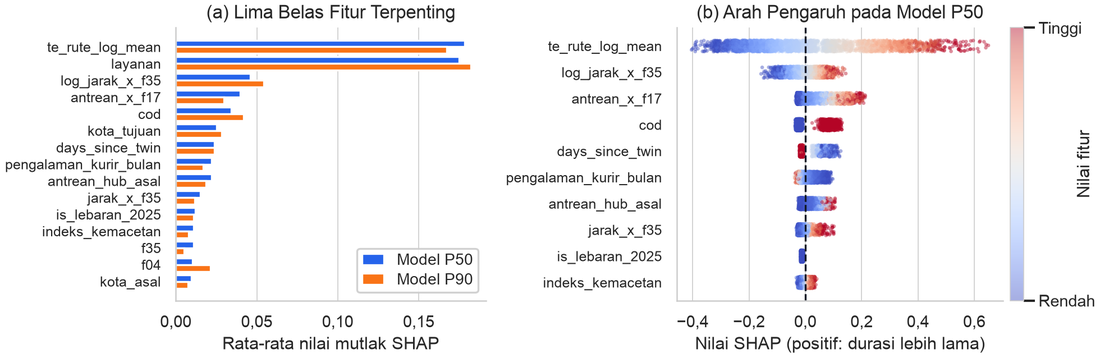

In [14]:
analisis = baca_hasil("task1_analysis.json")
for kunci, judul in (("by_layanan", "layanan"), ("by_pulau_tujuan", "pulau tujuan")):
    display(Markdown(f"**Error fold 3 terkalibrasi per {judul}**"))
    display(pd.DataFrame(analisis["error_breakdown"][kunci]))
tampilkan_gambar("task1_1f_error_breakdown.png")

display(Markdown("**15 fitur dengan rata-rata |SHAP| terbesar**"))
shap = analisis["shap_analysis"]
display(pd.DataFrame({
    "P50": pd.Series(shap["top15_p50_mean_abs_shap"]),
    "P90": pd.Series(shap["top15_p90_mean_abs_shap"]),
}).sort_values("P50", ascending=False))
tampilkan_gambar(shap["figure"])

Pemeriksaan akhir berkas `prediksi_regresi.csv` di *root* repositori: kolom, jumlah baris sama dengan
data uji, tanpa nilai kosong, dan `p90 ≥ p50` di setiap baris.

In [15]:
from src.config import PRED_REGRESI_PATH, REGRESI_TEST_PATH

prediksi = pd.read_csv(PRED_REGRESI_PATH)
uji = pd.read_csv(REGRESI_TEST_PATH, usecols=["id_paket"])
assert list(prediksi.columns) == ["id_paket", "p50", "p90"]
assert len(prediksi) == len(uji) and prediksi["id_paket"].equals(uji["id_paket"])
assert prediksi[["p50", "p90"]].notna().all().all()
assert (prediksi["p90"] >= prediksi["p50"]).all()
print(f"{PRED_REGRESI_PATH.name}: {len(prediksi):,} baris, kontrak terpenuhi")
display(prediksi.head())
display(prediksi[["p50", "p90"]].describe().T)

prediksi_regresi.csv: 60,000 baris, kontrak terpenuhi


,id_paket,p50,p90
0,P83639399,59.7839,76.6513
1,P26553951,112.2690,161.0615
2,P32537117,58.7876,80.6542
3,P28750760,61.2927,82.6842
4,P96580009,53.3558,67.1719


,count,mean,std,min,25%,50%,75%,max
p50,60000.0,70.3007,32.8661,16.3606,47.7349,62.7541,84.0975,379.4668
p90,60000.0,96.0815,46.4391,21.0434,65.0104,85.0831,114.0918,603.2990
